<a href="https://colab.research.google.com/github/mariamwahgee037-boop/Skin-Care/blob/main/skin_care.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

import os
import pandas as pd

print(os.listdir('/content'))

['.config', 'cosmetics.csv', 'sample_data']


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving cosmetics.csv to cosmetics.csv


In [ ]:


df = pd.read_csv('/content/cosmetics.csv')

print("Dataset shape:", df.shape)
print(df.head())

Dataset shape: (1472, 11)
         Label           Brand                                           Name  \
0  Moisturizer          LA MER                                Crème de la Mer   
1  Moisturizer           SK-II                       Facial Treatment Essence   
2  Moisturizer  DRUNK ELEPHANT                     Protini™ Polypeptide Cream   
3  Moisturizer          LA MER                    The Moisturizing Soft Cream   
4  Moisturizer    IT COSMETICS  Your Skin But Better™ CC+™ Cream with SPF 50+   

   Price  Rank                                        Ingredients  \
0    175   4.1  Algae (Seaweed) Extract, Mineral Oil, Petrolat...   
1    179   4.1  Galactomyces Ferment Filtrate (Pitera), Butyle...   
2     68   4.4  Water, Dicaprylyl Carbonate, Glycerin, Ceteary...   
3    175   3.8  Algae (Seaweed) Extract, Cyclopentasiloxane, P...   
4     38   4.1  Water, Snail Secretion Filtrate, Phenyl Trimet...   

   Combination  Dry  Normal  Oily  Sensitive  
0            1    1      

In [ ]:


df_clean = df.copy()
skin_types = ["Combination", "Dry", "Normal", "Oily", "Sensitive"]


print("=== Data Types ===")
print(df_clean.dtypes)
print("\n=== Missing Values ===")
print(df_clean.isna().sum())


for col in df_clean.select_dtypes(include="object").columns:
    df_clean[col] = df_clean[col].replace(r"^\s*$", pd.NA, regex=True)

df_clean["Price"] = pd.to_numeric(df_clean["Price"], errors="coerce")
df_clean["Rank"] = pd.to_numeric(df_clean["Rank"], errors="coerce")

print("\n=== Duplicate Rows ===", df_clean.duplicated().sum())
print("=== Prices <= 0 ===", (df_clean["Price"] <= 0).sum())
print("=== Ratings outside 0-5 ===",
      ((df_clean["Rank"] < 0) | (df_clean["Rank"] > 5)).sum())
for col in skin_types:
    print(col, sorted(df_clean[col].dropna().unique()))


df_clean = df_clean.drop_duplicates()
df_clean = df_clean.dropna(subset=["Label", "Brand", "Price", "Rank"])
df_clean = df_clean[df_clean["Price"] > 0]
df_clean = df_clean[df_clean["Rank"].between(0, 5)]

rated_df = df_clean[df_clean["Rank"] > 0].copy()

print("\nProducts after cleaning:", len(df_clean))
print("Rated products:", len(rated_df))

=== Data Types ===
Label           object
Brand           object
Name            object
Price            int64
Rank           float64
Ingredients     object
Combination      int64
Dry              int64
Normal           int64
Oily             int64
Sensitive        int64
dtype: object

=== Missing Values ===
Label          0
Brand          0
Name           0
Price          0
Rank           0
Ingredients    0
Combination    0
Dry            0
Normal         0
Oily           0
Sensitive      0
dtype: int64

=== Duplicate Rows === 0
=== Prices <= 0 === 0
=== Ratings outside 0-5 === 0
Combination [np.int64(0), np.int64(1)]
Dry [np.int64(0), np.int64(1)]
Normal [np.int64(0), np.int64(1)]
Oily [np.int64(0), np.int64(1)]
Sensitive [np.int64(0), np.int64(1)]

Products after cleaning: 1472
Rated products: 1453


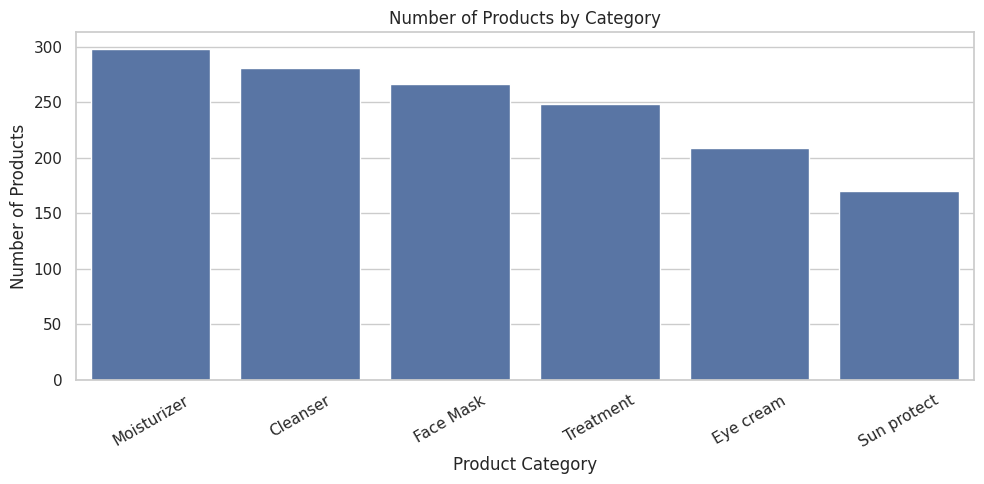

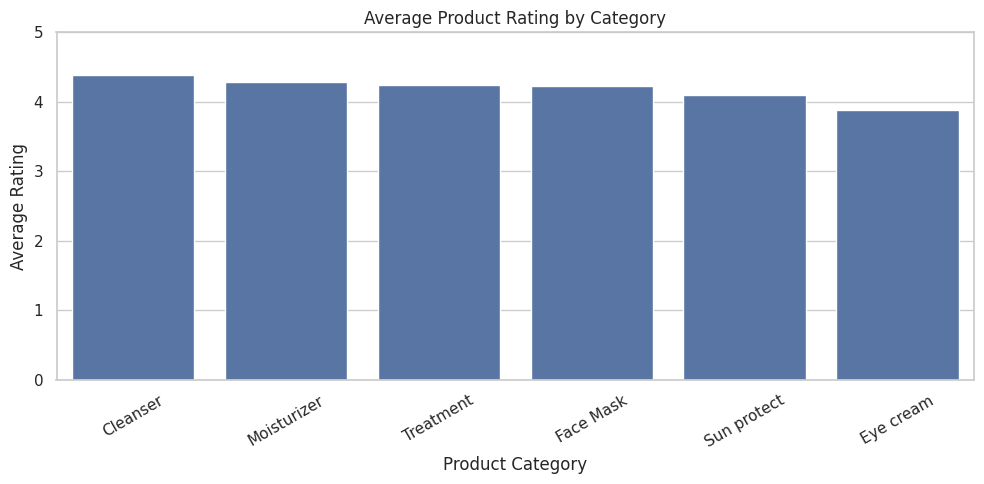

In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 5))
category_counts = df_clean["Laibel"].value_counts()
sns.barplot(
    x=category_counts.index,
    y=category_counts.values
)
plt.title("Number of Products by Category")
plt.xlabel("Product Category")
plt.ylabel("Number of Products")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()
avg_rating = rated_df.groupby("Label")["Rank"].mean().sort_values(
    ascending=False
)
plt.figure(figsize=(10, 5))
sns.barplot(
    x=avg_rating.index,
    y=avg_rating.values
)
plt.title("Average Product Rating by Category")
plt.xlabel("Product Category")
plt.ylabel("Average Rating")
plt.ylim(0, 5)
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


Products listed as suitable for each skin type:


,Number of Products
Combination,966
Normal,960
Dry,904
Oily,894
Sensitive,756


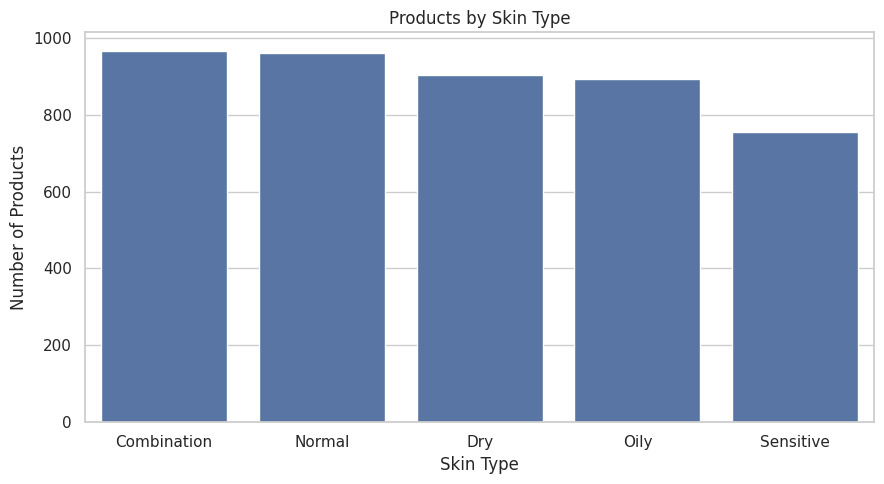

In [ ]:
skin_types = ["Combination", "Dry", "Normal", "Oily", "Sensitive"]
skin_counts = df_clean[skin_types].sum().sort_values(ascending=False)
print("Products listed as suitable for each skin type:")
display(skin_counts.to_frame(name="Number of Products"))
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(9, 5))
sns.barplot(
    x=skin_counts.index,
    y=skin_counts.values
)
plt.title("Products by Skin Type")
plt.xlabel("Skin Type")
plt.ylabel("Number of Products")
plt.tight_layout()
plt.show()


Price Analysis by Product Category:


,Average Price,Median Price,Minimum Price,Maximum Price
Label,,,,
Cleanser,32.60,28.0,4,95
Eye cream,63.60,52.0,5,260
Face Mask,42.62,36.0,3,250
Moisturizer,69.09,50.0,4,325
Sun protect,45.91,38.0,18,260
Treatment,79.18,64.5,18,370


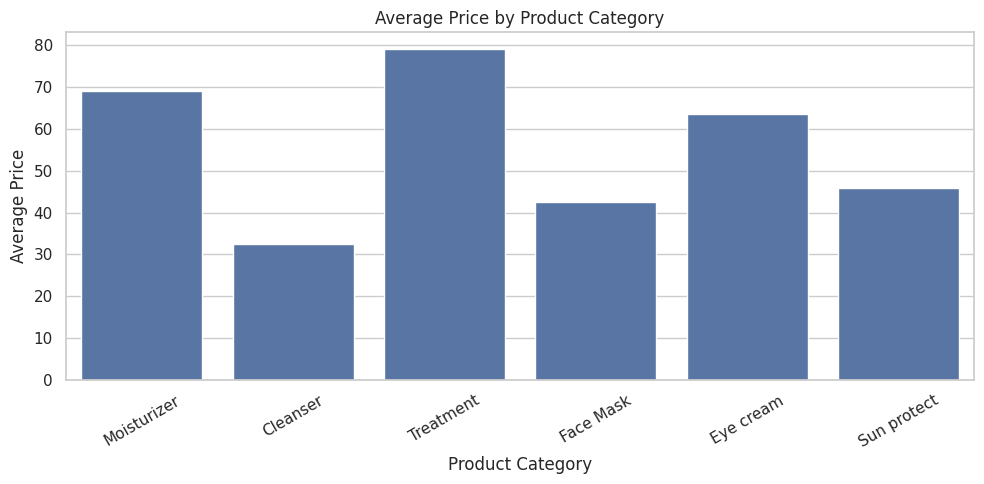

In [ ]:
price_analysis = df_clean.groupby("Label")["Price"].agg(
    ["mean", "median", "min", "max"]
).round(2)
price_analysis.columns = [
    "Average Price",
    "Median Price",
    "Minimum Price",
    "Maximum Price"
]
print("Price Analysis by Product Category:")
display(price_analysis)
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(10, 5))
sns.barplot(
    data=df,
    x="Label",
    y="Price",
    errorbar=None
)
plt.title("Average Price by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Average Price")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [ ]:
print("Number of products with zero rating:", (df["Rank"] == 0).sum())
rated_products = df_clean[df_clean["Rank"] > 0].copy()
print("Products with positive ratings:", len(rated_products))
print("\nAverage rating by category:")
display(
    rated_products.groupby("Label")["Rank"]
    .mean()
    .sort_values(ascending=False)
    .round(2)
    .to_frame("Average Rating")
)
print("\nTop 10 highest-rated products:")
display(
    rated_products[
        ["Name", "Brand", "Label", "Price", "Rank"]
    ]
    .sort_values("Rank", ascending=False)
    .head(10)
)

Number of products with zero rating: 19
Products with positive ratings: 1453

Average rating by category:


,Average Rating
Label,
Cleanser,4.39
Moisturizer,4.28
Treatment,4.24
Face Mask,4.23
Sun protect,4.10
Eye cream,3.88



Top 10 highest-rated products:


,Name,Brand,Label,Price,Rank
9,Little Miss Miracle Limited-Edition Crème de l...,LA MER,Moisturizer,325,5.0
848,Experiential Masks Set,SEPHORA COLLECTION,Face Mask,18,5.0
830,Face Mask Magic,SEPHORA COLLECTION,Face Mask,25,5.0
800,The Nightly Retinol + Peptide Anti-Aging Serum,BEAUTYBIO,Treatment,95,5.0
823,Silver Skin Savior Salicylic/Glycolic Acid Tre...,OMOROVICZA,Treatment,125,5.0
974,Sleeping Mask - Aloe Vera,SEPHORA COLLECTION,Face Mask,4,5.0
957,The Lifting and Firming Mask Mini,LA MER,Face Mask,75,5.0
953,Face Mask - Grape - Anti-pollution,SEPHORA COLLECTION,Face Mask,6,5.0
954,Make My Day Hydrating & Anti-Pollution UFO™ Ac...,FOREO,Face Mask,9,5.0
755,Doctor's Kit Gold Standard Anti-Aging Solution,DR. DENNIS GROSS SKINCARE,Treatment,59,5.0


In [ ]:
print("=== 1. DATA TYPES ===")
display(df_clean.dtypes.to_frame("Data Type"))


print("\n=== 2. MISSING VALUES ===")
display(df_clean.isna().sum().to_frame("Missing Values"))


text_cols = df_clean.select_dtypes(include="object").columns

for col in text_cols:
    df_clean[col] = df_clean[col].replace(
        r"^\s*$", pd.NA, regex=True
    )

print("\n=== 3. BLANK VALUES ===")
display(df_clean.isna().sum().to_frame("Missing / Blank Values"))


print("\n=== 4. DUPLICATE ROWS ===")
print("Duplicate rows:", df_clean.duplicated().sum())


df_clean["Price"] = pd.to_numeric(
    df_clean["Price"], errors="coerce"
)
df_clean["Rank"] = pd.to_numeric(
    df_clean["Rank"], errors="coerce"
)

print("\n=== 5. INVALID VALUES ===")
print("Missing or invalid prices:", df_clean["Price"].isna().sum())
print("Prices <= 0:", (df_clean["Price"] <= 0).sum())
print("Missing or invalid ratings:", df_clean["Rank"].isna().sum())
print(
    "Ratings outside 0–5:",
    ((df_clean["Rank"] < 0) | (df_clean["Rank"] > 5)).sum()
)


skin_types = [
    "Combination", "Dry", "Normal", "Oily", "Sensitive"
]

print("\n=== 6. SKIN TYPE VALUES ===")
for col in skin_types:
    print(f"{col}: {sorted(df_clean[col].dropna().unique())}")


print("\n=== 7. DATASET SUMMARY ===")
print("Rows:", df_clean.shape[0])
print("Columns:", df_clean.shape[1])
print("Product categories:", df_clean["Label"].nunique())
print("Unique brands:", df_clean["Brand"].nunique())

display(df_clean[["Price", "Rank"]].describe())



=== 1. DATA TYPES ===


,Data Type
Label,object
Brand,object
Name,object
Price,int64
Rank,float64
Ingredients,object
Combination,int64
Dry,int64
Normal,int64
Oily,int64



=== 2. MISSING VALUES ===


,Missing Values
Label,0
Brand,0
Name,0
Price,0
Rank,0
Ingredients,0
Combination,0
Dry,0
Normal,0
Oily,0



=== 3. BLANK VALUES ===


,Missing / Blank Values
Label,0
Brand,0
Name,0
Price,0
Rank,0
Ingredients,0
Combination,0
Dry,0
Normal,0
Oily,0



=== 4. DUPLICATE ROWS ===
Duplicate rows: 0

=== 5. INVALID VALUES ===
Missing or invalid prices: 0
Prices <= 0: 0
Missing or invalid ratings: 0
Ratings outside 0–5: 0

=== 6. SKIN TYPE VALUES ===
Combination: [np.int64(0), np.int64(1)]
Dry: [np.int64(0), np.int64(1)]
Normal: [np.int64(0), np.int64(1)]
Oily: [np.int64(0), np.int64(1)]
Sensitive: [np.int64(0), np.int64(1)]

=== 7. DATASET SUMMARY ===
Rows: 1472
Columns: 11
Product categories: 6
Unique brands: 116


,Price,Rank
count,1472.000000,1472.000000
mean,55.584239,4.153261
std,45.014429,0.633918
min,3.000000,0.000000
25%,30.000000,4.000000
50%,42.500000,4.300000
75%,68.000000,4.500000
max,370.000000,5.000000


In [ ]:
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# Define "Price Range" column based on the Price boundaries
bins = [0, 25, 50, 100, float('inf')]
labels = ["Budget (<=25)", "Mid-range (25-50)", "Premium (50-100)", "Luxury (>100)"]
df_clean["Price Range"] = pd.cut(df_clean["Price"], bins=bins, labels=labels, right=True)

price_counts = df_clean["Price Range"].value_counts().sort_index()

fig_price = make_subplots(
    rows=2,
    cols=2,
    specs=[
        [{"type": "xy", "colspan": 2}, None],
        [{"type": "pie"}, {"type": "xy"}]
    ],
    subplot_titles=(
        "Price Distribution",
        "Products by Price Range",
        "Price Spread & Outliers"
    ),
    vertical_spacing=0.20,
    horizontal_spacing=0.12,
    row_heights=[0.58, 0.42]
)

fig_price.add_trace(
    go.Histogram(
        x=df_clean["Price"],
        nbinsx=30,
        marker_color="#6478B9",
        marker_line_color="white",
        marker_line_width=0.7,
        hovertemplate="Price: %{x}<br>Products: %{y}<extra></extra>"
    ),
    row=1, col=1
)
fig_price.add_trace(
    go.Pie(
        labels=price_counts.index.astype(str),
        values=price_counts.values,
        hole=0.58,
        sort=False,
        textinfo="percent",
        textposition="inside",
        marker=dict(
            colors=["#A9B8D8", "#6478B9", "#E6B566", "#D88787"],
            line=dict(color="white", width=2)
        ),
        hovertemplate="%{label}<br>Products: %{value}<br>Share: %{percent}<extra></extra>"
    ),
    row=2, col=1
)

fig_price.add_trace(
    go.Box(
        y=df_clean["Price"],
        name="Product Price",
        boxpoints="outliers",
        marker_color="#D88787",
        line_color="#6478B9",
        fillcolor="rgba(100,120,185,0.20)",
        hovertemplate="Price: %{y}<extra></extra>"
    ),
    row=2, col=2
)

fig_price.update_layout(
    title=dict(
        text=f"SKIN CARE ANALYTICS<br><sup>Price Analysis | {len(df_clean):,} Products</sup>",

        x=0.5,
        xanchor="center"
    ),
    template="plotly_white",
    height=850,
    showlegend=False,
    font=dict(family="Arial", size=12, color="#30364A"),
    margin=dict(l=55, r=35, t=110, b=55),
    paper_bgcolor="#F8F9FC",
    plot_bgcolor="white"
)

fig_price.update_xaxes(
    title_text="Product Price",
    showgrid=False
)
fig_price.update_yaxes(
    title_text="Number of Products",
    gridcolor="#E8EAF1"
)
fig_price.update_yaxes(
    title_text="Product Price",
    row=2, col=2,
    gridcolor="#E8EAF1"
)

fig_price.show()

In [ ]:

import plotly.express as px


rated_df = df_clean[df_clean["Rank"] > 0].copy()

fig_scatter = px.scatter(
    rated_df,
    x="Price",
    y="Rank",
    color="Label",
    hover_name="Name",
    hover_data={
        "Brand": True,
        "Price": True,
        "Rank": ":.2f",
        "Label": True
    },
    title="Do Higher-Priced Products Get Better Ratings?",
    labels={
        "Price": "Product Price",
        "Rank": "Rating (out of 5)",
        "Label": "Product Category"
    },
    template="plotly_white",
    opacity=0.7
)

fig_scatter.update_traces(marker=dict(size=8))
fig_scatter.update_layout(
    height=600,
    title_x=0.5,
    legend_title_text="Product Category",
    margin=dict(l=60, r=30, t=90, b=60)
)

fig_scatter.update_yaxes(range=[0, 5.2], dtick=1)
fig_scatter.show()


In [ ]:

import numpy as np
import plotly.graph_objects as go

rated_df = df_clean[df_clean["Rank"] > 0].copy()


correlation = rated_df["Price"].corr(rated_df["Rank"])

if correlation >= 0.7:
    interpretation = "Strong positive relationship"
elif correlation >= 0.3:
    interpretation = "Moderate positive relationship"
elif correlation > 0:
    interpretation = "Weak positive relationship"
elif correlation <= -0.7:
    interpretation = "Strong negative relationship"
elif correlation <= -0.3:
    interpretation = "Moderate negative relationship"
elif correlation < 0:
    interpretation = "Weak negative relationship"
else:
    interpretation = "No linear relationship"

print(f"Products analyzed: {len(rated_df)}")
print(f"Pearson correlation: {correlation:.3f}")
print(f"Interpretation: {interpretation}")


fig_corr = go.Figure(
    go.Indicator(
        mode="number",
        value=correlation,
        number={"valueformat": ".3f"},
        title={"text": "Price vs. Rating<br><sup>Pearson Correlation</sup>"},
    )
)

fig_corr.update_layout(
    template="plotly_white",
    height=250,
    margin=dict(t=50, b=20, l=30, r=30)
)

fig_corr.show()


Products analyzed: 1453
Pearson correlation: -0.006
Interpretation: Weak negative relationship


In [ ]:


import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots

df_dashboard = df_clean.copy()

rated_df = df_dashboard[df_dashboard["Rank"] > 0].copy()

print("Dashboard data is ready")
print("Total products:", len(df_dashboard))
print("Unique brands:", df_dashboard["Brand"].nunique())
print("Average price:", round(df_dashboard["Price"].mean(), 2))
print("Average rating:", round(rated_df["Rank"].mean(), 2))
print("Product categories:", df_dashboard["Label"].nunique())

Dashboard data is ready
Total products: 1472
Unique brands: 116
Average price: 55.58
Average rating: 4.21
Product categories: 6


In [ ]:

import plotly.graph_objects as go
from plotly.subplots import make_subplots

PINK = "#D98CA3"
DARK_PINK = "#A95778"
MAUVE = "#9C89B8"
PEACH = "#E9B7A5"
LAVENDER = "#D9CBE8"
BG = "#FFF8FA"
TEXT = "#453844"
MUTED = "#887784"

category_counts = df_dashboard["Label"].value_counts()

category_rating = (
    rated_df.groupby("Label")["Rank"]
    .mean()
    .sort_values(ascending=True)
)

category_price = (
    df_dashboard.groupby("Label")["Price"]
    .mean()
    .sort_values(ascending=True)
)

skin_columns = ["Combination", "Dry", "Normal", "Oily", "Sensitive"]
skin_counts = df_dashboard[skin_columns].sum().sort_values(ascending=False)

fig_final = make_subplots(
    rows=3,
    cols=4,
    specs=[
        [
            {"type": "indicator"},
            {"type": "indicator"},
            {"type": "indicator"},
            {"type": "indicator"}
        ],
        [
            {"type": "domain", "colspan": 2},
            None,
            {"type": "xy", "colspan": 2},
            None
        ],
        [
            {"type": "xy", "colspan": 2},
            None,
            {"type": "xy", "colspan": 2},
            None
        ]
    ],
    subplot_titles=(
        "TOTAL PRODUCTS",
        "UNIQUE BRANDS",
        "AVERAGE PRICE",
        "AVERAGE RATING",
        "Product Category Distribution",
        "Average Rating by Category",
        "Products by Skin Type",
        "Average Price by Category"
    ),
    row_heights=[0.20, 0.40, 0.40],
    vertical_spacing=0.15,
    horizontal_spacing=0.10
)

kpis = [
    (len(df_dashboard), "#D98CA3", 1),
    (df_dashboard["Brand"].nunique(), "#9C89B8", 2),
    (df_dashboard["Price"].mean(), "#E9B7A5", 3),
    (rated_df["Rank"].mean(), "#A95778", 4)
]

for value, color, col in kpis:
    fig_final.add_trace(
        go.Indicator(
            mode="number",
            value=value,
            number={
                "font": {"size": 32, "color": color},
                "valueformat": ".2f" if col in [3, 4] else ",.0f",
                "suffix": " / 5" if col == 4 else ""
            },
            domain={"x": [0, 1], "y": [0, 1]}
        ),
        row=1, col=col
    )


fig_final.add_trace(
    go.Pie(
        labels=category_counts.index,
        values=category_counts.values,
        hole=0.62,
        sort=False,
        marker=dict(
            colors=[PINK, MAUVE, PEACH, DARK_PINK, LAVENDER, "#E7AFC0"],
            line=dict(color="#FFFFFF", width=3)
        ),
        textinfo="percent",
        textfont=dict(size=12, color=TEXT),
        hovertemplate="<b>%{label}</b><br>Products: %{value}<br>Share: %{percent}<extra></extra>"
    ),
    row=2, col=1
)


fig_final.add_trace(
    go.Bar(
        x=category_rating.values,
        y=category_rating.index,
        orientation="h",
        marker=dict(
            color=category_rating.values,
            colorscale=[[0, "#E9B7C7"], [1, "#A95778"]],
            line=dict(width=0)
        ),
        text=[f"{v:.2f}" for v in category_rating.values],
        textposition="outside",
        cliponaxis=False,
        hovertemplate="<b>%{y}</b><br>Average rating: %{x:.2f}/5<extra></extra>"
    ),
    row=2, col=3
)


fig_final.add_trace(
    go.Bar(
        x=skin_counts.index,
        y=skin_counts.values,
        marker=dict(
            color=[PINK, MAUVE, PEACH, DARK_PINK, LAVENDER],
            line=dict(width=0)
        ),
        text=skin_counts.values,
        textposition="outside",
        cliponaxis=False,
        hovertemplate="<b>%{x}</b><br>Products: %{y}<extra></extra>"
    ),
    row=3, col=1
)


fig_final.add_trace(
    go.Bar(
        x=category_price.values,
        y=category_price.index,
        orientation="h",
        marker=dict(
            color=category_price.values,
            colorscale=[[0, "#E9B7C7"], [1, "#9C89B8"]],
            line=dict(width=0)
        ),
        text=[f"${v:.2f}" for v in category_price.values],
        textposition="outside",
        cliponaxis=False,
        hovertemplate="<b>%{y}</b><br>Average price: %{x:.2f}<extra></extra>"
    ),
    row=3, col=3
)

fig_final.update_layout(
    title=dict(
        text=(
            "<b>SKINCARE ANALYTICS</b>"
            "<br><sup>Beauty Product Insights | Data-driven Overview</sup>"
        ),
        x=0.04,
        xanchor="left",
        font=dict(size=26, color=TEXT)
    ),
    height=1050,
    paper_bgcolor=BG,
    plot_bgcolor="#FFFFFF",
    font=dict(family="Arial", color=TEXT, size=12),
    margin=dict(l=55, r=65, t=125, b=55),
    showlegend=True,
    legend=dict(
        orientation="h",
        yanchor="bottom",
        y=-0.06,
        xanchor="center",
        x=0.5,
        font=dict(size=10, color=MUTED)
    ),
    bargap=0.42
)


fig_final.update_xaxes(
    showgrid=True,
    gridcolor="#F1E6EC",
    zeroline=False,
    showline=False,
    tickfont=dict(color=MUTED),
    row=2, col=3
)
fig_final.update_yaxes(
    showgrid=False,
    tickfont=dict(color=TEXT),
    row=2, col=3
)

fig_final.update_xaxes(
    showgrid=False,
    tickfont=dict(color=MUTED),
    row=3, col=1
)
fig_final.update_yaxes(
    showgrid=True,
    gridcolor="#F1E6EC",
    zeroline=False,
    tickfont=dict(color=MUTED),
    row=3, col=1
)

fig_final.update_xaxes(
    showgrid=True,
    gridcolor="#F1E6EC",
    zeroline=False,
    tickfont=dict(color=MUTED),
    row=3, col=3
)
fig_final.update_yaxes(
    showgrid=False,
    tickfont=dict(color=TEXT),
    row=3, col=3
)

fig_final.update_annotations(
    font=dict(size=13, color=TEXT)
)

fig_final.update_layout(showlegend=False)
fig_final.show()
